<a href="https://colab.research.google.com/github/subornakter/AI_Assignment/blob/main/Mushroom_Edibility_Classification_Lab11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSE 4101 – Practical Lab Assignment 11
## Complete Machine Learning Workflow for Mushroom Edibility Classification

**Dataset:** Mushroom Classification (UCI / Kaggle) – `mushrooms.csv`
**Target:** `class` (`e` = edible, `p` = poisonous)
**Language / platform:** Python 3, Google Colab / Jupyter Notebook
**Random seed:** `SEED = 42` (used for every split and every model)

> ⚠️ **Safety statement.** This notebook is a *dataset-analysis exercise only*. The models built here must **never** be used to decide whether a wild mushroom is safe to eat (see Task 10).

**Workflow:** Collect data → Explore → Split labeled data → Fit preprocessing on training data → Train models → Validate and tune → Select model → Evaluate on untouched test set → Predict and interpret.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import beta

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

EDIBLE_C, POISON_C = "#2a78b5", "#e08a1e"   # colour-blind friendly pair

print("Python libs -> pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| seaborn", sns.__version__)
print("Random seed :", SEED)

Python libs -> pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1 | seaborn 0.13.2
Random seed : 42


---
# Task 1 – Read the dataset and profile it

Steps: load the CSV, check the real shape/column names against the assignment text, count categories per feature and look for missing-value symbols.
(`keep_default_na=False` makes sure pandas does not silently convert any code letter into `NaN`; the missing-value symbol in this dataset is the literal text `?`.)

In [ ]:
CSV_PATH = "mushrooms.csv"
if not os.path.exists(CSV_PATH):
    try:                                   # Google Colab: upload the file when asked
        from google.colab import files
        print("Please upload mushrooms.csv ...")
        up = files.upload()
        CSV_PATH = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError("Put mushrooms.csv next to this notebook (or download it from "
                                "https://www.kaggle.com/uciml/mushroom-classification).")

df = pd.read_csv(CSV_PATH, keep_default_na=False)
print("Shape:", df.shape, "(rows, columns)")
print("Columns:", list(df.columns))
df.head()

Shape: (8124, 23) (rows, columns)
Columns: ['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,p,w,o,e,n,a,g


In [ ]:
df.info()
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

In [ ]:
# Category profile: number of categories, the category codes, and count of '?' per column
profile = pd.DataFrame({
    "n_categories": df.nunique(),
    "categories": {c: " ".join(sorted(df[c].unique())) for c in df.columns},
    "count_of_?": (df == "?").sum(),
})
profile["%_of_?"] = (profile["count_of_?"] / len(df) * 100).round(2)
profile

,n_categories,categories,count_of_?,%_of_?
class,2,e p,0,0.00
cap-shape,6,b c f k s x,0,0.00
cap-surface,4,f g s y,0,0.00
cap-color,10,b c e g n p r u w y,0,0.00
bruises,2,f t,0,0.00
odor,9,a c f l m n p s y,0,0.00
gill-attachment,2,a f,0,0.00
gill-spacing,2,c w,0,0.00
gill-size,2,b n,0,0.00
gill-color,12,b e g h k n o p r u w y,0,0.00


In [ ]:
# Category counts for every column
for c in df.columns:
    print(f"{c:28s}", df[c].value_counts().to_dict())

class                        {'e': 4208, 'p': 3916}
cap-shape                    {'x': 3656, 'f': 3152, 'k': 828, 'b': 452, 's': 32, 'c': 4}
cap-surface                  {'y': 3244, 's': 2556, 'f': 2320, 'g': 4}
cap-color                    {'n': 2284, 'g': 1840, 'e': 1500, 'y': 1072, 'w': 1040, 'b': 168, 'p': 144, 'c': 44, 'u': 16, 'r': 16}
bruises                      {'f': 4748, 't': 3376}
odor                         {'n': 3528, 'f': 2160, 'y': 576, 's': 576, 'a': 400, 'l': 400, 'p': 256, 'c': 192, 'm': 36}
gill-attachment              {'f': 7914, 'a': 210}
gill-spacing                 {'c': 6812, 'w': 1312}
gill-size                    {'b': 5612, 'n': 2512}
gill-color                   {'b': 1728, 'p': 1492, 'w': 1202, 'n': 1048, 'g': 752, 'h': 732, 'u': 492, 'k': 408, 'e': 96, 'y': 86, 'o': 64, 'r': 24}
stalk-shape                  {'t': 4608, 'e': 3516}
stalk-root                   {'b': 3776, '?': 2480, 'e': 1120, 'c': 556, 'r': 192}
stalk-surface-above-ring     {'s': 5176, 'k

### Observations (Task 1)

* **Shape and names match the Kaggle file:** 8,124 rows × 23 columns (22 descriptors + `class`). The real column names are hyphenated (`cap-shape`, `cap-surface`, `gill-attachment`, `stalk-root`, …), whereas the assignment text writes them in plain words ("cap shape", "gill characteristics"). Every column is a single-letter category code, so there are no numeric columns, and `bruises` is stored as `t`/`f` (some tools display it as Boolean).
* **Missing-value symbol:** the only symbol is `?`, and it appears in **one** column, `stalk-root` (2,480 rows = 30.53 %). The other 22 columns are complete. There are no duplicate rows.
* **`veil-type` has one single value (`p`) in all 8,124 rows**, so it carries no information.
* **Target:** 4,208 edible (51.8 %) vs 3,916 poisonous (48.2 %) – almost balanced.

---
# Task 2 – Exploratory analysis

Descriptive statistics, missing-value counts, target distribution and outcome proportions by feature.

In [ ]:
print("Descriptive statistics (all columns are categorical):")
display(df.describe().T)

print("\nMissing-value counts (after turning the '?' symbol into NaN):")
miss = df.replace("?", np.nan).isna().sum()
display(miss[miss > 0].to_frame("missing_count").assign(percent=lambda t: (t.missing_count / len(df) * 100).round(2)))
print("Columns with no missing values:", int((miss == 0).sum()), "of", len(miss))

Descriptive statistics (all columns are categorical):


,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728



Missing-value counts (after turning the '?' symbol into NaN):


,missing_count,percent
stalk-root,2480,30.53


Columns with no missing values: 22 of 23


       count  percent
class                
e       4208     51.8
p       3916     48.2


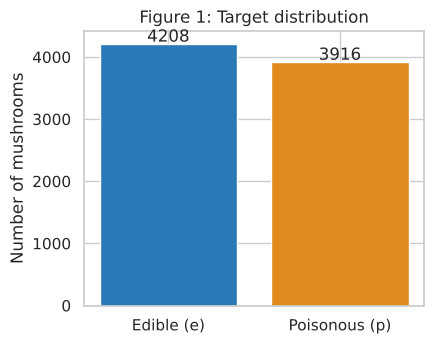

In [ ]:
# Target distribution
counts = df["class"].value_counts()
print(counts.to_frame("count").assign(percent=(counts / len(df) * 100).round(2)))

fig, ax = plt.subplots(figsize=(4.5, 3.6))
bars = ax.bar(["Edible (e)", "Poisonous (p)"], [counts["e"], counts["p"]], color=[EDIBLE_C, POISON_C])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 40, f"{int(b.get_height())}", ha="center")
ax.set_title("Figure 1: Target distribution"); ax.set_ylabel("Number of mushrooms")
plt.tight_layout(); plt.show()

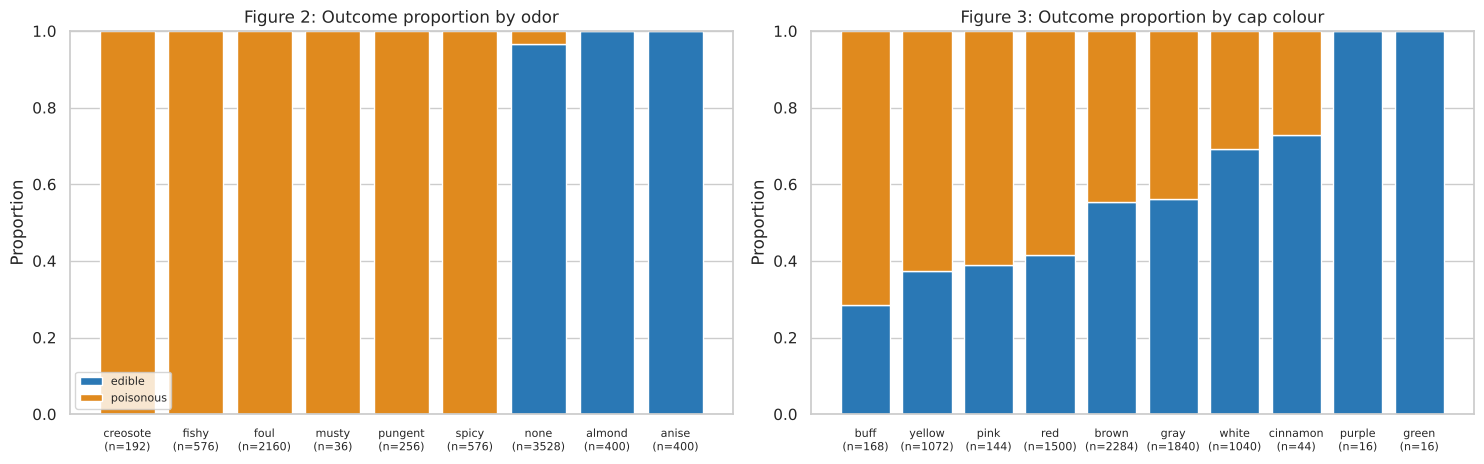

Share of poisonous mushrooms by odor:


,% poisonous
odor,
creosote,100.0
fishy,100.0
foul,100.0
musty,100.0
pungent,100.0
spicy,100.0
none,3.4
almond,0.0
anise,0.0


Share of poisonous mushrooms by cap colour:


,% poisonous
cap-color,
buff,71.4
yellow,62.7
pink,61.1
red,58.4
brown,44.7
gray,43.9
white,30.8
cinnamon,27.3
purple,0.0


In [ ]:
ODOR = {"a": "almond", "l": "anise", "c": "creosote", "y": "fishy", "f": "foul",
        "m": "musty", "n": "none", "p": "pungent", "s": "spicy"}
CAPCOL = {"n": "brown", "b": "buff", "c": "cinnamon", "g": "gray", "r": "green",
          "p": "pink", "u": "purple", "e": "red", "w": "white", "y": "yellow"}

def poison_share(col, labels=None, ax=None, title=None):
    ct = pd.crosstab(df[col], df["class"])
    share = ct["p"] / ct.sum(axis=1)
    order = share.sort_values(ascending=False).index
    ct, share = ct.loc[order], share.loc[order]
    names = [f"{(labels or {}).get(k, k)}\n(n={ct.loc[k].sum()})" for k in order]
    ax.bar(names, 1 - share, color=EDIBLE_C, label="edible")
    ax.bar(names, share, bottom=1 - share, color=POISON_C, label="poisonous")
    ax.set_ylim(0, 1); ax.set_ylabel("Proportion"); ax.set_title(title or col)
    ax.tick_params(axis="x", labelsize=8)
    return share

# Figure 2 & 3: odor and cap colour
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
share_odor = poison_share("odor", ODOR, axes[0], "Figure 2: Outcome proportion by odor")
share_cap = poison_share("cap-color", CAPCOL, axes[1], "Figure 3: Outcome proportion by cap colour")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

print("Share of poisonous mushrooms by odor:");      display((share_odor * 100).round(1).rename(index=ODOR).to_frame("% poisonous"))
print("Share of poisonous mushrooms by cap colour:"); display((share_cap * 100).round(1).rename(index=CAPCOL).to_frame("% poisonous"))

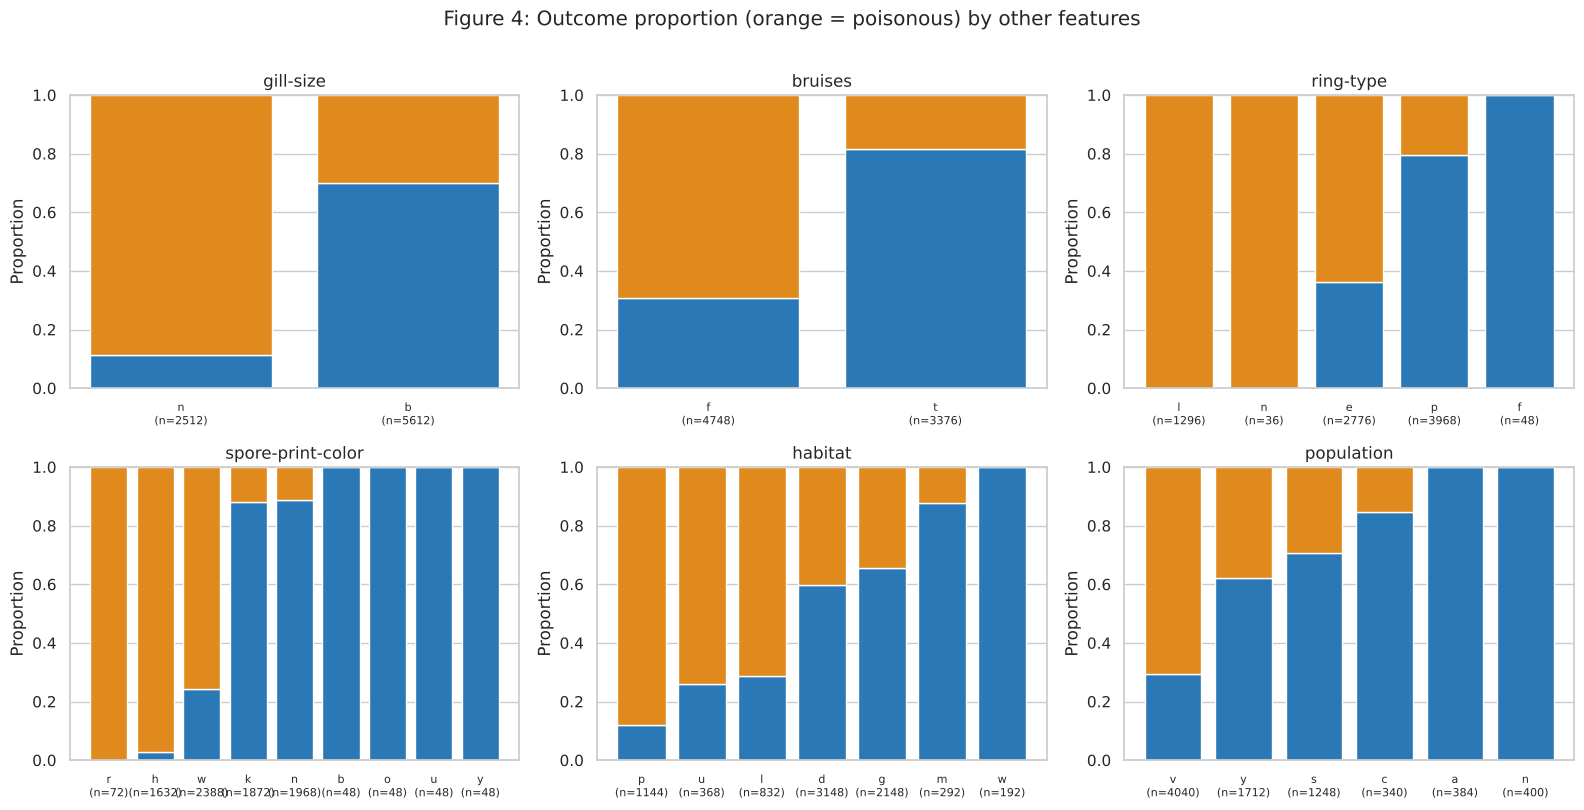

,single-feature majority-class accuracy
odor,0.985
spore-print-color,0.868
gill-color,0.805
ring-type,0.775
stalk-surface-above-ring,0.774
stalk-surface-below-ring,0.766
gill-size,0.756
bruises,0.744
population,0.722
stalk-color-above-ring,0.716


In [ ]:
# Figure 4: other categorical features
others = ["gill-size", "bruises", "ring-type", "spore-print-color", "habitat", "population"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), others):
    poison_share(col, ax=ax, title=col)
fig.suptitle("Figure 4: Outcome proportion (orange = poisonous) by other features", y=1.01)
plt.tight_layout(); plt.show()

# A compact numeric summary: how 'pure' is each feature? (accuracy of predicting the majority class inside every category)
purity = {c: (df.groupby(c)["class"].agg(lambda s: s.value_counts().iloc[0]).sum() / len(df)) for c in df.columns.drop("class")}
display(pd.Series(purity).sort_values(ascending=False).round(3).to_frame("single-feature majority-class accuracy").head(10))

### Observations (Task 2)

1. **The classes are balanced (Figure 1: 51.8 % edible, 48.2 % poisonous).** Plain accuracy is therefore not misleading, and no re-sampling is needed. Still, recall of the poisonous class is reported separately because that is the dangerous error.
2. **Odor is an extremely strong signal (Figure 2).** Creosote, fishy, foul, musty, pungent and spicy mushrooms are **100 % poisonous**; almond and anise are **0 % poisonous**; only the "none" group (n = 3,528) is mixed, with 3.4 % poisonous (120 mushrooms). Predicting the majority class inside each odor group gives 98.5 % accuracy on the full data – far more than any other single feature (next best: `spore-print-color`, 86.8 %).
3. **Cap colour is a weak, overlapping signal (Figure 3).** Poisonous shares range from 71.4 % (buff) down to 27.3 % (cinnamon), so almost every colour occurs in both classes. Purple and green show 0 % poisonous, but with only 16 mushrooms each this is too small to trust. Cap colour alone cannot decide edibility.
4. **Other features (Figure 4)** such as `spore-print-color`, `gill-color`, `ring-type` and `habitat` separate the classes partly but not perfectly, which is why a model combining several features is needed.

---
# Task 3 – Separate the label from the inputs and handle `?` values

**Decisions**

1. `y` = the `class` column, encoded `1 = poisonous`, `0 = edible`. Poisonous is the **positive class** because the dangerous mistake is calling a poisonous mushroom edible (a false negative), so *recall of poisonous* is the key metric.
2. `X` = all other columns. The label is **removed** from the inputs, so the model cannot see it.
3. The only missing-value symbol is `?` (in `stalk-root`). It is converted to `NaN` and then filled with the constant category `"missing"`. Reason: `?` covers about a third of the rows, so deleting them would throw away a lot of data, and *not knowing the stalk root* may itself carry information. Filling with a fixed word uses **no statistics from the data**, so it cannot leak information between train/validation/test.
4. `veil-type` has a single value (`p`) for every row, so it carries no information and is dropped.

In [ ]:
data = df.replace("?", np.nan)
print("Missing values before handling:\n", data.isna().sum()[lambda s: s > 0])

# 1) target
y = (data["class"] == "p").astype(int)          # 1 = poisonous, 0 = edible

# 2) inputs without the label
X = data.drop(columns=["class"])

# 4) constant columns carry no information
const_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
print("\nConstant columns dropped:", const_cols)
X = X.drop(columns=const_cols)

# 3) '?' -> 'missing' category
X = X.fillna("missing")

assert "class" not in X.columns, "label leaked into features!"
assert X.isna().sum().sum() == 0 and not (X == "?").any().any()

print("\nX shape:", X.shape, "| y shape:", y.shape)
print("Target encoding:", y.value_counts().rename({0: "edible (0)", 1: "poisonous (1)"}).to_dict())
print("\nstalk-root after handling:", X["stalk-root"].value_counts().to_dict())
X.head()

Missing values before handling:
 stalk-root    2480
dtype: int64

Constant columns dropped: ['veil-type']

X shape: (8124, 21) | y shape: (8124,)
Target encoding: {'edible (0)': 4208, 'poisonous (1)': 3916}

stalk-root after handling: {'b': 3776, 'missing': 2480, 'e': 1120, 'c': 556, 'r': 192}


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,w,o,e,n,a,g


### Significance (Task 3)

* The printed output shows that the inputs `X` now have **21 columns** (23 − `class` − `veil-type`) and 8,124 rows, that **no `?` remains** (`stalk-root` now contains the category `missing` for the 2,480 former `?` rows), and that `y` is encoded 1 = poisonous (3,916) / 0 = edible (4,208). The assertion `"class" not in X.columns` passed.
* **Significance:** keeping `class` out of the inputs prevents *target leakage* (a model that can see the answer would trivially score 100 %). Using a fixed `"missing"` category keeps all rows and treats "unknown stalk root" as information in its own right. Because this step learns nothing from the data (no mean/mode is computed), it is safe to do before the split without leaking validation/test information.

---
# Task 4 – Stratified 70 / 15 / 15 split and encoding fitted on training rows only

* First split: 70 % train, 30 % temporary, **stratified** on `y`.
* Second split: the 30 % is cut in half → 15 % validation, 15 % test, again stratified.
* The `OneHotEncoder` is **fitted only on `X_train`**; validation and test are only *transformed*. `handle_unknown="ignore"` makes a category that never appeared in training become an all-zero block instead of crashing.

,rows,share_of_data_%,edible,poisonous,poisonous_%
train,5686,69.99,2945,2741,48.21
validation,1219,15.00,631,588,48.24
test,1219,15.00,632,587,48.15


Overall poisonous %: 48.2


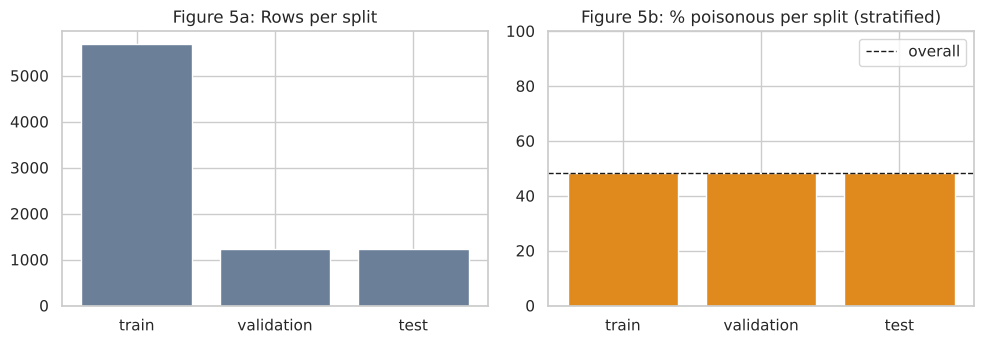

In [ ]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

split_tbl = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "share_of_data_%": [round(len(s) / len(y) * 100, 2) for s in (y_train, y_val, y_test)],
    "edible": [(s == 0).sum() for s in (y_train, y_val, y_test)],
    "poisonous": [(s == 1).sum() for s in (y_train, y_val, y_test)],
    "poisonous_%": [round(s.mean() * 100, 2) for s in (y_train, y_val, y_test)],
}, index=["train", "validation", "test"])
display(split_tbl)
print("Overall poisonous %:", round(y.mean() * 100, 2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(split_tbl.index, split_tbl["rows"], color="#6b7f99"); ax[0].set_title("Figure 5a: Rows per split")
ax[1].bar(split_tbl.index, split_tbl["poisonous_%"], color=POISON_C); ax[1].set_ylim(0, 100)
ax[1].axhline(y.mean() * 100, color="k", ls="--", lw=1, label="overall"); ax[1].legend()
ax[1].set_title("Figure 5b: % poisonous per split (stratified)")
plt.tight_layout(); plt.show()

In [ ]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
Xtr = encoder.fit_transform(X_train)        # FIT on training rows only
Xva = encoder.transform(X_val)              # transform only
Xte = encoder.transform(X_test)             # transform only
feature_names = encoder.get_feature_names_out()

print("Encoded shapes  train:", Xtr.shape, "| validation:", Xva.shape, "| test:", Xte.shape)
print("Encoded feature count:", len(feature_names), "(from", X.shape[1], "categorical columns)")

# Did validation / test contain any category the encoder never saw in training?
unseen = {}
for col, cats in zip(X.columns, encoder.categories_):
    extra = (set(X_val[col]) | set(X_test[col])) - set(cats)
    if extra:
        unseen[col] = sorted(extra)
print("Categories in val/test that are unseen in train:", unseen if unseen else "none")

Encoded shapes  train: (5686, 116) | validation: (1219, 116) | test: (1219, 116)
Encoded feature count: 116 (from 21 categorical columns)
Categories in val/test that are unseen in train: none


### Why this matters (Task 4)

* **Stratification worked:** the share of poisonous mushrooms is 48.21 % (train, 5,686 rows), 48.24 % (validation, 1,219 rows) and 48.15 % (test, 1,219 rows) versus 48.2 % overall, so each subset is representative (Figure 5b).
* **Encoding:** the one-hot encoder was fitted on the training rows only (116 binary columns) and merely applied to validation and test. Those two subsets contain no category that is unseen in training, and `handle_unknown="ignore"` would protect against it anyway.
* **Why it matters:** anything "learned" from data (here, the category vocabulary) must come from the training rows only; otherwise information about validation/test rows would leak into the pipeline and the later scores would be too optimistic. Separate validation and test subsets also let us tune on one and report on a truly untouched one.

---
# Task 5 – Train Decision Tree, Logistic Regression and Random Forest

**Method / settings / libraries** – all from `scikit-learn`; every model uses `random_state = 42`. These are the *baseline* settings; they are tuned in Task 6.

| Model | Class | Settings |
|---|---|---|
| Decision Tree | `sklearn.tree.DecisionTreeClassifier` | defaults (unlimited depth, `min_samples_leaf=1`, gini) |
| Logistic Regression | `sklearn.linear_model.LogisticRegression` | `C=1.0`, `max_iter=1000`, L2 penalty |
| Random Forest | `sklearn.ensemble.RandomForestClassifier` | `n_estimators=200`, defaults otherwise |

In [ ]:
def scores(model, X_, y_):
    p = model.predict(X_)
    return {"accuracy": accuracy_score(y_, p),
            "precision": precision_score(y_, p, zero_division=0),
            "recall": recall_score(y_, p, zero_division=0),
            "f1": f1_score(y_, p, zero_division=0)}

baseline = {
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}
rows = []
for name, m in baseline.items():
    m.fit(Xtr, y_train)                                   # ONLY training data is used for fitting
    s_tr, s_va = scores(m, Xtr, y_train), scores(m, Xva, y_val)
    rows.append({"model": name, "train_acc": s_tr["accuracy"], "val_acc": s_va["accuracy"],
                 "val_precision": s_va["precision"], "val_recall(poisonous)": s_va["recall"], "val_f1": s_va["f1"]})
display(pd.DataFrame(rows).set_index("model").round(4))

,train_acc,val_acc,val_precision,val_recall(poisonous),val_f1
model,,,,,
Decision Tree,1.0000,1.0000,1.0,1.0000,1.0000
Logistic Regression,0.9998,0.9992,1.0,0.9983,0.9991
Random Forest,1.0000,1.0000,1.0,1.0000,1.0000


In [ ]:
# ---- Evidence that no held-out information was used ----
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_val) + len(X_test) == len(X)
print("1) train / validation / test row indices are pairwise disjoint            -> OK")

assert Xtr.shape[0] == len(y_train) and encoder.n_features_in_ == X.shape[1]
print("2) every model was fitted with fit(Xtr, y_train) only                     -> OK")

# the encoder's vocabulary comes from the training rows only
same = all(set(c) == set(X_train[col].unique()) for col, c in zip(X.columns, encoder.categories_))
print("3) encoder categories == categories seen in the training rows              ->", "OK" if same else "CHECK")

print("4) the test set (Xte, y_test) has not been scored by any model so far; it is first used in Task 8")

1) train / validation / test row indices are pairwise disjoint            -> OK
2) every model was fitted with fit(Xtr, y_train) only                     -> OK
3) encoder categories == categories seen in the training rows              -> OK
4) the test set (Xte, y_test) has not been scored by any model so far; it is first used in Task 8


### Interpretation (Task 5)

* With default settings the Decision Tree and the Random Forest already reach **100 % accuracy on both train and validation**; Logistic Regression reaches 99.98 % (train) and 99.92 % (validation), i.e. one poisonous validation mushroom (recall 0.9983) was missed.
* The four checks above show that no held-out information was used: the three subsets are disjoint, models were fitted with `fit(Xtr, y_train)` only, the encoder vocabulary equals the training vocabulary, and the test set has not been scored yet.
* **Interpretation:** the problem is almost perfectly separable by the descriptors, so even untuned models are nearly perfect. Differences between models will therefore be tiny, and tuning can only be judged on very small margins.

---
# Task 6 – Tune hyper-parameters on the validation set

* **Decision Tree:** `max_depth` ∈ {1,2,3,4,5,6,8,10,None} × `min_samples_leaf` ∈ {1,2,5,10,20,50}
* **Random Forest:** `max_depth` ∈ {3,5,8,None} × `min_samples_leaf` ∈ {1,5,20} (200 trees)
* **Logistic Regression:** `C` ∈ {0.001, 0.01, 0.1, 1, 10, 100}

All models are trained on the **training** rows and compared on the **validation** rows – the test set is not touched.

**Selection rule (decided before looking at results):** because missing a poisonous mushroom is the costly error, rank by **validation recall of the poisonous class**, then **validation F1**, then prefer the **simpler model** (fewer leaves / smaller `C`). Across model families, remaining ties are broken in the order Decision Tree → Logistic Regression → Random Forest (most to least interpretable).

In [ ]:
def pack(prefix, m, Xa, ya):
    s = scores(m, Xa, ya)
    return {f"{prefix}_{k}": v for k, v in s.items()}

# ---- Decision Tree grid ----
dt_rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    for leaf in [1, 2, 5, 10, 20, 50]:
        m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=SEED).fit(Xtr, y_train)
        dt_rows.append({"max_depth": str(d), "min_samples_leaf": leaf,
                        "n_leaves": m.get_n_leaves(), **pack("train", m, Xtr, y_train), **pack("val", m, Xva, y_val)})
dt_res = pd.DataFrame(dt_rows)

# ---- Random Forest grid ----
rf_rows = []
for d in [3, 5, 8, None]:
    for leaf in [1, 5, 20]:
        m = RandomForestClassifier(n_estimators=200, max_depth=d, min_samples_leaf=leaf,
                                   random_state=SEED, n_jobs=-1).fit(Xtr, y_train)
        rf_rows.append({"max_depth": str(d), "min_samples_leaf": leaf,
                        "n_leaves": np.mean([t.get_n_leaves() for t in m.estimators_]),
                        **pack("train", m, Xtr, y_train), **pack("val", m, Xva, y_val)})
rf_res = pd.DataFrame(rf_rows)

# ---- Logistic Regression grid ----
lr_rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    m = LogisticRegression(C=C, max_iter=2000, random_state=SEED).fit(Xtr, y_train)
    lr_rows.append({"C": C, **pack("train", m, Xtr, y_train), **pack("val", m, Xva, y_val)})
lr_res = pd.DataFrame(lr_rows)

sort_cols, sort_asc = ["val_recall", "val_f1", "n_leaves"], [False, False, True]
print("Decision Tree - top 8 configurations (by selection rule)")
display(dt_res.sort_values(sort_cols, ascending=sort_asc).head(8).round(4).reset_index(drop=True))
print("Random Forest - all configurations")
display(rf_res.sort_values(sort_cols, ascending=sort_asc).round(4).reset_index(drop=True))
print("Logistic Regression - all configurations")
display(lr_res.sort_values(["val_recall", "val_f1", "C"], ascending=[False, False, True]).round(4).reset_index(drop=True))

Decision Tree - top 8 configurations (by selection rule)


,max_depth,min_samples_leaf,n_leaves,train_accuracy,train_precision,train_recall,train_f1,val_accuracy,val_precision,val_recall,val_f1
0,6,1,13,1.0000,1.0000,1.0,1.0000,1.0,1.0,1.0,1.0
1,6,5,13,0.9995,0.9989,1.0,0.9995,1.0,1.0,1.0,1.0
2,8,1,13,1.0000,1.0000,1.0,1.0000,1.0,1.0,1.0,1.0
3,8,5,13,0.9995,0.9989,1.0,0.9995,1.0,1.0,1.0,1.0
4,10,1,13,1.0000,1.0000,1.0,1.0000,1.0,1.0,1.0,1.0
5,10,5,13,0.9995,0.9989,1.0,0.9995,1.0,1.0,1.0,1.0
6,None,1,13,1.0000,1.0000,1.0,1.0000,1.0,1.0,1.0,1.0
7,None,5,13,0.9995,0.9989,1.0,0.9995,1.0,1.0,1.0,1.0


Random Forest - all configurations


,max_depth,min_samples_leaf,n_leaves,train_accuracy,train_precision,train_recall,train_f1,val_accuracy,val_precision,val_recall,val_f1
0,8,1,23.400,1.0000,1.0,1.0000,1.0000,1.0000,1.0,1.0000,1.0000
1,None,1,33.035,1.0000,1.0,1.0000,1.0000,1.0000,1.0,1.0000,1.0000
2,8,5,22.765,0.9993,1.0,0.9985,0.9993,0.9975,1.0,0.9949,0.9974
3,None,5,29.245,0.9993,1.0,0.9985,0.9993,0.9975,1.0,0.9949,0.9974
4,8,20,20.225,0.9984,1.0,0.9967,0.9984,0.9967,1.0,0.9932,0.9966
5,None,20,23.500,0.9984,1.0,0.9967,0.9984,0.9967,1.0,0.9932,0.9966
6,5,1,13.125,0.9896,1.0,0.9785,0.9891,0.9926,1.0,0.9847,0.9923
7,5,20,12.415,0.9887,1.0,0.9767,0.9882,0.9918,1.0,0.9830,0.9914
8,5,5,13.070,0.9893,1.0,0.9777,0.9887,0.9918,1.0,0.9830,0.9914
9,3,5,6.295,0.9668,1.0,0.9310,0.9643,0.9623,1.0,0.9218,0.9593


Logistic Regression - all configurations


,C,train_accuracy,train_precision,train_recall,train_f1,val_accuracy,val_precision,val_recall,val_f1
0,10.000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,100.000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,1.000,0.9998,1.0000,0.9996,0.9998,0.9992,1.0000,0.9983,0.9991
3,0.100,0.9988,1.0000,0.9974,0.9987,0.9967,1.0000,0.9932,0.9966
4,0.010,0.9838,0.9911,0.9752,0.9831,0.9861,0.9914,0.9796,0.9855
5,0.001,0.9274,0.9747,0.8719,0.9205,0.9262,0.9788,0.8656,0.9188


In [ ]:
best_dt = dt_res.sort_values(sort_cols, ascending=sort_asc).iloc[0]
best_rf = rf_res.sort_values(sort_cols, ascending=sort_asc).iloc[0]
best_lr = lr_res.sort_values(["val_recall", "val_f1", "C"], ascending=[False, False, True]).iloc[0]

def to_depth(v): return None if v == "None" else int(v)

tuned = {
    "Decision Tree": DecisionTreeClassifier(max_depth=to_depth(best_dt["max_depth"]),
                        min_samples_leaf=int(best_dt["min_samples_leaf"]), random_state=SEED).fit(Xtr, y_train),
    "Logistic Regression": LogisticRegression(C=float(best_lr["C"]), max_iter=2000, random_state=SEED).fit(Xtr, y_train),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=to_depth(best_rf["max_depth"]),
                        min_samples_leaf=int(best_rf["min_samples_leaf"]), random_state=SEED, n_jobs=-1).fit(Xtr, y_train),
}
config_txt = {
    "Decision Tree": f"max_depth={best_dt['max_depth']}, min_samples_leaf={int(best_dt['min_samples_leaf'])}",
    "Logistic Regression": f"C={best_lr['C']}",
    "Random Forest": f"max_depth={best_rf['max_depth']}, min_samples_leaf={int(best_rf['min_samples_leaf'])}, n_estimators=200",
}
rank = {"Decision Tree": 0, "Logistic Regression": 1, "Random Forest": 2}

comp = []
for name, m in tuned.items():
    s_tr, s_va = scores(m, Xtr, y_train), scores(m, Xva, y_val)
    comp.append({"model": name, "best_config": config_txt[name],
                 "train_acc": s_tr["accuracy"], "val_acc": s_va["accuracy"], "val_precision": s_va["precision"],
                 "val_recall": s_va["recall"], "val_f1": s_va["f1"], "rank": rank[name]})
comp = pd.DataFrame(comp)
display(comp.drop(columns="rank").set_index("model").round(4))

selected_name = comp.sort_values(["val_recall", "val_f1", "rank"], ascending=[False, False, True]).iloc[0]["model"]
selected_model = tuned[selected_name]
print("SELECTED MODEL (validation evidence only):", selected_name, "->", config_txt[selected_name])

,best_config,train_acc,val_acc,val_precision,val_recall,val_f1
model,,,,,,
Decision Tree,"max_depth=6, min_samples_leaf=1",1.0,1.0,1.0,1.0,1.0
Logistic Regression,C=10.0,1.0,1.0,1.0,1.0,1.0
Random Forest,"max_depth=8, min_samples_leaf=1, n_estimators=200",1.0,1.0,1.0,1.0,1.0


SELECTED MODEL (validation evidence only): Decision Tree -> max_depth=6, min_samples_leaf=1


### Interpretation (Task 6)

* **Decision Tree:** every configuration with `max_depth ≥ 6` and `min_samples_leaf` of 1 or 5 reaches 100 % validation accuracy/recall/F1 with the same 13 leaves (the tree stops growing because all leaves are pure). Shallow trees (depth 1–3) are clearly worse, and a large `min_samples_leaf = 50` costs accuracy (98.5 % at depth ≥ 5).
* **Random Forest:** `max_depth = 8, min_samples_leaf = 1` reaches 100 %; shallow forests (`max_depth = 3`) drop to 92 % recall for poisonous mushrooms.
* **Logistic Regression:** `C = 10` and `C = 100` reach 100 %; strong regularisation (`C = 0.001`) under-fits badly (validation recall 0.866 – it would call about 13 % of poisonous mushrooms edible).
* **Comparison:** all three tuned models tie at 100 % on every validation metric, so validation evidence cannot rank them on accuracy. By the rule stated above (fewest leaves / most interpretable on ties) the **Decision Tree with `max_depth = 6`, `min_samples_leaf = 1` (13 leaves)** is selected. Differences between the approaches: the tree is a small set of readable if-then rules; logistic regression is linear in the one-hot features and needs weak regularisation to fit; the forest averages 200 trees and is the most complex, with no measurable gain here.
* *Caution:* the choice rests on simplicity, not on a demonstrated accuracy advantage.

---
# Task 7 – Train vs validation performance and model complexity

For the decision tree, complexity is controlled by `max_depth` (and `min_samples_leaf`). Below, depth is increased with `min_samples_leaf = 1` to show the raw effect of complexity, then the whole tuning grid is shown as a heat-map.

,max_depth,n_leaves,train_acc,val_acc,val_recall(poisonous),gap(train-val)
0,1,2,0.8881,0.8811,0.9745,0.0071
1,2,4,0.9546,0.9442,0.9694,0.0104
2,3,7,0.9854,0.9861,0.9949,-0.0007
3,4,10,0.9940,0.9926,0.9966,0.0014
4,5,12,0.9998,0.9984,0.9966,0.0015
5,6,13,1.0000,1.0000,1.0000,0.0000
6,7,13,1.0000,1.0000,1.0000,0.0000
7,8,13,1.0000,1.0000,1.0000,0.0000
8,9,13,1.0000,1.0000,1.0000,0.0000
9,10,13,1.0000,1.0000,1.0000,0.0000


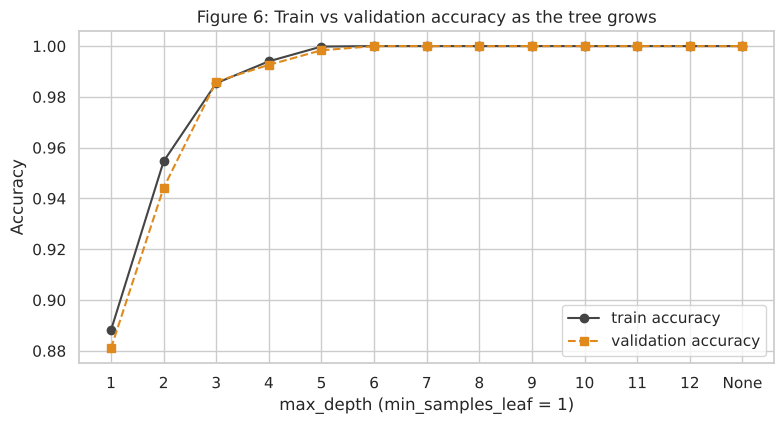

In [ ]:
depth_rows = []
for d in list(range(1, 13)) + [None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(Xtr, y_train)
    depth_rows.append({"max_depth": str(d), "n_leaves": m.get_n_leaves(),
                       "train_acc": accuracy_score(y_train, m.predict(Xtr)),
                       "val_acc": accuracy_score(y_val, m.predict(Xva)),
                       "val_recall(poisonous)": recall_score(y_val, m.predict(Xva))})
depth_df = pd.DataFrame(depth_rows)
depth_df["gap(train-val)"] = depth_df["train_acc"] - depth_df["val_acc"]
display(depth_df.round(4))

fig, ax = plt.subplots(figsize=(8, 4.4))
xs = depth_df["max_depth"].astype(str)
ax.plot(xs, depth_df["train_acc"], "o-", color="#444", label="train accuracy")
ax.plot(xs, depth_df["val_acc"], "s--", color=POISON_C, label="validation accuracy")
ax.set_xlabel("max_depth (min_samples_leaf = 1)"); ax.set_ylabel("Accuracy"); ax.legend()
ax.set_title("Figure 6: Train vs validation accuracy as the tree grows")
plt.tight_layout(); plt.show()

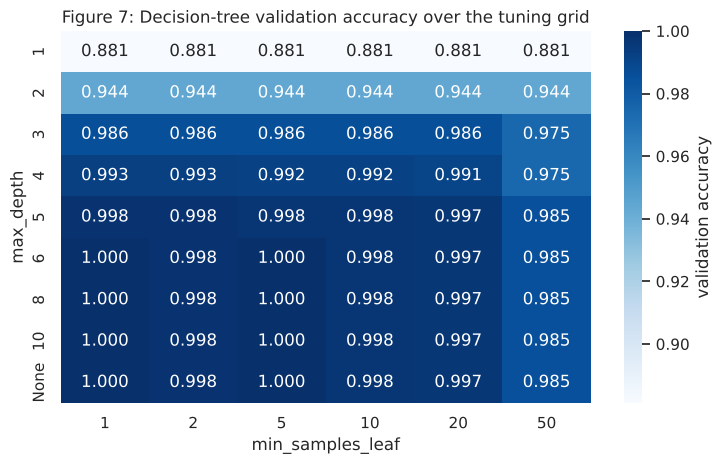

In [ ]:
piv = dt_res.pivot(index="max_depth", columns="min_samples_leaf", values="val_accuracy")
order = [str(d) for d in [1, 2, 3, 4, 5, 6, 8, 10, "None"]]
piv = piv.loc[order]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "validation accuracy"}, ax=ax)
ax.set_title("Figure 7: Decision-tree validation accuracy over the tuning grid")
plt.tight_layout(); plt.show()

In [ ]:
# train vs validation for the three tuned models (generalisation gap)
gap = comp[["model", "best_config", "train_acc", "val_acc"]].copy()
gap["gap(train-val)"] = gap["train_acc"] - gap["val_acc"]
display(gap.set_index("model").round(4))

,best_config,train_acc,val_acc,gap(train-val)
model,,,,
Decision Tree,"max_depth=6, min_samples_leaf=1",1.0,1.0,0.0
Logistic Regression,C=10.0,1.0,1.0,0.0
Random Forest,"max_depth=8, min_samples_leaf=1, n_estimators=200",1.0,1.0,0.0


### Interpretation (Task 7)

* **Under-fitting at low complexity:** with `max_depth = 1` (2 leaves) the tree reaches only 88.8 % train / 88.1 % validation; depth 2 gives 95.5 % / 94.4 %; depth 3 about 98.5 % / 98.6 %. Both scores rise together, which is the signature of too little complexity, not of over-fitting.
* **Plateau, no over-fitting:** from depth 6 onward the tree has 13 leaves (it cannot grow further because every leaf is pure) and scores 100 % on both train and validation. The train–validation gap stays at about 0.01 or less for all depths and is exactly 0 for the three tuned models (last table). The classic picture of validation accuracy falling when the model gets too complex does not appear, because the data has almost no noise to memorise.
* **Heat-map (Figure 7):** accuracy is 100 % for `max_depth ≥ 6` with `min_samples_leaf` 1 or 5, slightly lower (99.7–99.8 %) with leaf sizes 2, 10 and 20, and lowest (98.5 %) with leaf size 50, where leaves are forced to be too coarse.
* **Choice:** depth 6 is the smallest depth that reaches 100 % validation accuracy and recall; deeper trees add no leaves and no accuracy, so the simplest sufficient model is chosen using validation evidence only.

---
# Task 8 – Final evaluation on the untouched test set

The model was **chosen on validation evidence only** (Task 6). The test set is now used exactly once for the final report. Metrics treat *poisonous* as the positive class.

In [ ]:
pred_te = selected_model.predict(Xte)
cm = confusion_matrix(y_test, pred_te, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Selected model:", selected_name, "(", config_txt[selected_name], ")")
print(f"Test rows: {len(y_test)}  (edible={int((y_test==0).sum())}, poisonous={int((y_test==1).sum())})\n")
print(classification_report(y_test, pred_te, target_names=["edible", "poisonous"], digits=4))

res = {"accuracy": accuracy_score(y_test, pred_te), "precision (poisonous)": precision_score(y_test, pred_te),
       "recall (poisonous)": recall_score(y_test, pred_te), "F1 (poisonous)": f1_score(y_test, pred_te)}
display(pd.Series(res).round(4).to_frame("test score"))

print(f"False negatives (poisonous predicted edible - the DANGEROUS error): {fn}")
print(f"False positives (edible predicted poisonous - a harmless waste)   : {fp}")

# 95% Clopper-Pearson exact interval for the recall of the poisonous class
k, n = tp, tp + fn
lo = beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0
hi = beta.ppf(0.975, k + 1, n - k) if k < n else 1.0
print(f"\nRecall(poisonous) = {k}/{n} = {k/n:.4f}; 95% exact confidence interval = [{lo:.4f}, {hi:.4f}]")

Selected model: Decision Tree ( max_depth=6, min_samples_leaf=1 )
Test rows: 1219  (edible=632, poisonous=587)

              precision    recall  f1-score   support

      edible     1.0000    1.0000    1.0000       632
   poisonous     1.0000    1.0000    1.0000       587

    accuracy                         1.0000      1219
   macro avg     1.0000    1.0000    1.0000      1219
weighted avg     1.0000    1.0000    1.0000      1219



,test score
accuracy,1.0
precision (poisonous),1.0
recall (poisonous),1.0
F1 (poisonous),1.0


False negatives (poisonous predicted edible - the DANGEROUS error): 0
False positives (edible predicted poisonous - a harmless waste)   : 0

Recall(poisonous) = 587/587 = 1.0000; 95% exact confidence interval = [0.9937, 1.0000]


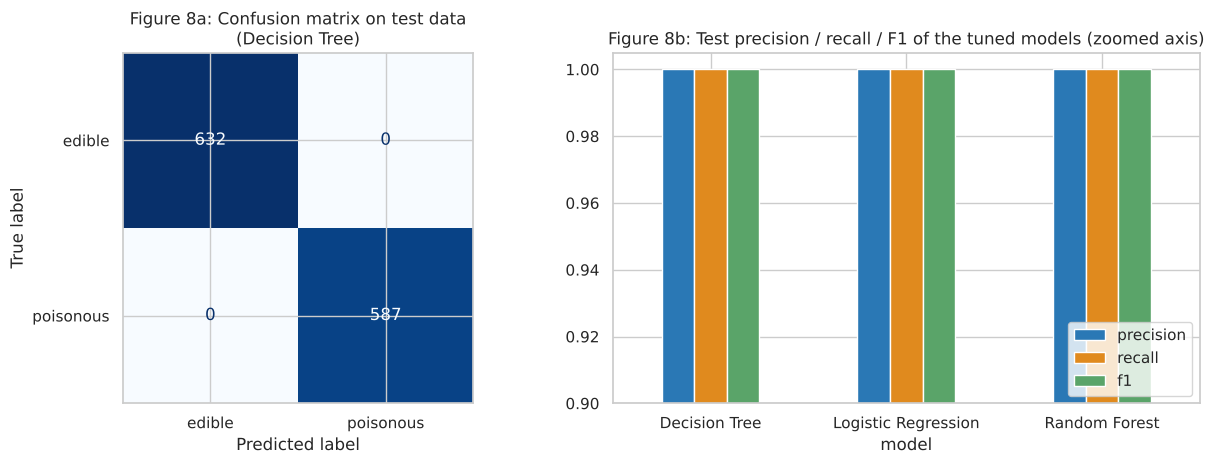

,accuracy,precision,recall,f1,false_negatives
model,,,,,
Decision Tree,1.0,1.0,1.0,1.0,0
Logistic Regression,1.0,1.0,1.0,1.0,0
Random Forest,1.0,1.0,1.0,1.0,0


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ConfusionMatrixDisplay(cm, display_labels=["edible", "poisonous"]).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title(f"Figure 8a: Confusion matrix on test data\n({selected_name})")

# comparison of the three tuned models on the test set (for reporting only - selection was already done on validation)
cmp_rows = []
for name, m in tuned.items():
    p = m.predict(Xte)
    cmp_rows.append({"model": name, "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                     "recall": recall_score(y_test, p), "f1": f1_score(y_test, p),
                     "false_negatives": int(((y_test == 1) & (p == 0)).sum())})
cmp_te = pd.DataFrame(cmp_rows).set_index("model")
cmp_te[["precision", "recall", "f1"]].plot(kind="bar", ax=ax[1], rot=0, color=["#2a78b5", "#e08a1e", "#5aa469"])
ax[1].set_ylim(0.9, 1.005); ax[1].set_title("Figure 8b: Test precision / recall / F1 of the tuned models (zoomed axis)")
ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()
display(cmp_te.round(4))

### Interpretation, uncertainty and limitations (Task 8)

* **Result on the untouched test set (1,219 mushrooms: 632 edible, 587 poisonous):** accuracy, precision, recall and F1 are all **1.0000**; the confusion matrix has **0 false negatives and 0 false positives** (632 true negatives, 587 true positives). The Logistic Regression and Random Forest also score perfectly (Figure 8b), so the test set does not separate the models either.
* **Uncertainty:** "587 of 587" does not mean the true recall is 100 %. The 95 % exact (Clopper–Pearson) confidence interval for the poisonous-class recall is **[0.9937, 1.0000]** – up to roughly 6 missed poisonous mushrooms per 1,000 cannot be ruled out statistically.
* **Limitations:** (1) one random split and only 1,219 test rows; (2) a random split puts very similar records (the same species described in nearly the same way) into both training and test data, so the test set is an easy, in-distribution check; (3) perfect scores describe *this file*, not mushrooms in general. A split by species would be a much harder and more honest test.

---
# Task 9 – Predictions for five held-out records

Five records are drawn from the **test set** with a fixed seed (3 poisonous + 2 edible, so both classes are visible). The selected model predicts each one, and the prediction is compared with the true class.

In [ ]:
rng = np.random.RandomState(SEED)
pos_idx = rng.choice(y_test[y_test == 1].index, 3, replace=False)
neg_idx = rng.choice(y_test[y_test == 0].index, 2, replace=False)
five = list(pos_idx) + list(neg_idx)

pos_in_test = [list(X_test.index).index(i) for i in five]
Xfive = Xte[pos_in_test]
proba = selected_model.predict_proba(Xfive)[:, 1]
pred = selected_model.predict(Xfive)

lab = {0: "edible", 1: "poisonous"}
table = pd.DataFrame({
    "original_row": five,
    "odor": [ODOR[v] for v in X_test.loc[five, "odor"]],
    "cap-color": [CAPCOL[v] for v in X_test.loc[five, "cap-color"]],
    "gill-size": X_test.loc[five, "gill-size"].values,
    "spore-print-color": X_test.loc[five, "spore-print-color"].values,
    "actual": [lab[v] for v in y_test.loc[five]],
    "predicted": [lab[v] for v in pred],
    "P(poisonous)": proba.round(4),
    "correct": ["yes" if a == b else "NO" for a, b in zip(y_test.loc[five], pred)],
}).reset_index(drop=True)
display(table)
print(f"Correct: {(y_test.loc[five].values == pred).sum()} / 5")

,original_row,odor,cap-color,gill-size,spore-print-color,actual,predicted,P(poisonous),correct
0,5560,foul,white,b,h,poisonous,poisonous,1.0,yes
1,5227,foul,brown,n,w,poisonous,poisonous,1.0,yes
2,5240,foul,white,b,h,poisonous,poisonous,1.0,yes
3,3772,none,brown,b,n,edible,edible,0.0,yes
4,4647,none,purple,n,h,edible,edible,0.0,yes


Correct: 5 / 5


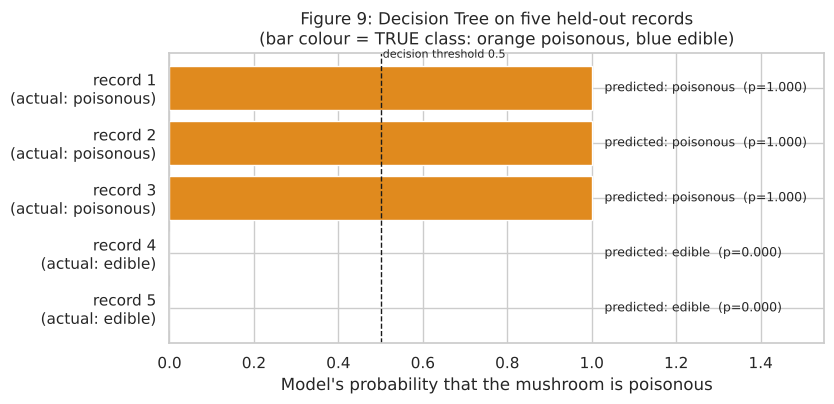

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
colors = [POISON_C if a == 1 else EDIBLE_C for a in y_test.loc[five]]
ax.barh([f"record {i+1}\n(actual: {lab[a]})" for i, a in enumerate(y_test.loc[five])], proba, color=colors)
ax.axvline(0.5, color="k", ls="--", lw=1)
ax.text(0.505, -0.55, "decision threshold 0.5", fontsize=8)
for i, (p, pr) in enumerate(zip(proba, pred)):
    ax.text(1.03, i, f"predicted: {lab[pr]}  (p={p:.3f})", va="center", fontsize=9)
ax.set_xlim(0, 1.55); ax.invert_yaxis(); ax.set_xlabel("Model's probability that the mushroom is poisonous")
ax.set_title(f"Figure 9: {selected_name} on five held-out records\n(bar colour = TRUE class: orange poisonous, blue edible)")
plt.tight_layout(); plt.show()

### Interpretation (Task 9)

* **Result:** all **5 / 5** held-out records are predicted correctly: the three poisonous ones (foul odor) get P(poisonous) = 1.000 and the two edible ones (no odor) get 0.000.
* **Interpretation and limitations:** five records are far too few to measure performance; they only illustrate the behaviour already quantified in Task 8. The probabilities of exactly 0 or 1 come from pure leaves of a decision tree (the share of training samples in the leaf), so they do not mean the model is "certain" in a real-world sense. The model does not rely on odor alone – importance is also given to `stalk-root`, `stalk-surface-below-ring` and `spore-print-color` (Figure 10) – and the edible record with a *purple* cap shows that cap colour does not drive the decision.

---
# Task 10 – Dataset bias, safety statement, results summary and conclusion

## ⚠️ Safety statement
**These models must never be used to guide real foraging decisions.** A classifier trained on this table cannot tell anyone whether a wild mushroom is safe to eat. A single wrong "edible" prediction can mean liver failure or death, and no accuracy figure on a benchmark file changes that.

## Dataset bias – what this data is and is not

,test accuracy,test recall (poisonous)
always predict the majority class,0.5185,0.000
one-feature rule: odor only,0.9861,0.971
selected model: Decision Tree,1.0000,1.000


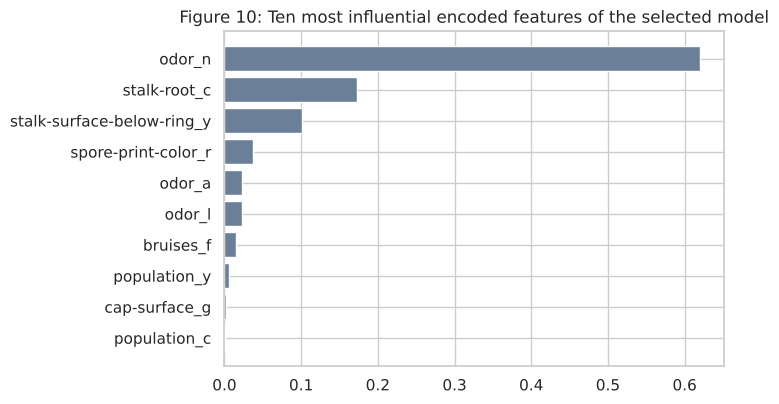

,importance
odor_n,0.6203
stalk-root_c,0.1726
stalk-surface-below-ring_y,0.1009
spore-print-color_r,0.0369
odor_a,0.0231
odor_l,0.0230
bruises_f,0.0146
population_y,0.0060
cap-surface_g,0.0021
population_c,0.0007


Rows: 8124 | distinct complete feature combinations: 8124


In [ ]:
# Numeric evidence for the discussion
# (a) how much of the 'performance' is explained by trivially simple rules?
majority = int(y_train.mean() >= 0.5)
maj_acc = accuracy_score(y_test, np.full(len(y_test), majority))

# odor-only rule learned from TRAINING rows (majority class per odor), applied to test rows
odor_rule = (y_train.groupby(X_train["odor"]).mean() >= 0.5).astype(int)
odor_pred = X_test["odor"].map(odor_rule).fillna(majority).astype(int)
odor_acc = accuracy_score(y_test, odor_pred)
odor_rec = recall_score(y_test, odor_pred)

summary = pd.DataFrame({
    "test accuracy": [maj_acc, odor_acc, cmp_te.loc[selected_name, "accuracy"]],
    "test recall (poisonous)": [recall_score(y_test, np.full(len(y_test), majority)), odor_rec, cmp_te.loc[selected_name, "recall"]],
}, index=["always predict the majority class", "one-feature rule: odor only", f"selected model: {selected_name}"])
display(summary.round(4))

# (b) which features does the selected model rely on?
if hasattr(selected_model, "feature_importances_"):
    imp = pd.Series(selected_model.feature_importances_, index=feature_names)
else:
    imp = pd.Series(np.abs(selected_model.coef_[0]), index=feature_names)
top = imp.sort_values(ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(top.index, top.values, color="#6b7f99")
ax.set_title("Figure 10: Ten most influential encoded features of the selected model")
plt.tight_layout(); plt.show()
display(top[::-1].round(4).to_frame("importance"))

# (c) how many species / how repetitive is the data?
print("Rows:", len(df), "| distinct complete feature combinations:", len(df.drop(columns='class').drop_duplicates()))

### Dataset bias and unexpected outcomes

* **Where the data come from.** According to the UCI documentation, the records describe hypothetical samples of **23 species of gilled mushrooms** taken from a North-American field guide, each labelled *definitely edible*, *definitely poisonous* or *unknown edibility / not recommended* – and the last group is merged into "poisonous". So (a) the data cover a tiny slice of mushroom species and of one region, (b) the rows are idealised, expert-coded descriptions, not field photographs or real specimens, and (c) the `p` label partly means "not recommended", not "proven toxic".
* **Artificial class balance.** The 52 % / 48 % split is a result of how the file was assembled, not the share of dangerous mushrooms in nature.
* **Near-duplicate records.** All 8,124 rows are different, but they are many variations of the same few species, so a random split puts near-twins into train and test and inflates the test result.
* **Unexpected outcomes (numbers above).** (1) Three very different model families all reach **100 % on validation and test**; no over-fitting appeared and tuning had almost nothing to improve. (2) **One feature, odor, is enough for 98.6 % test accuracy** (rule learned from training rows) – but that simple rule only catches 97.1 % of poisonous mushrooms. The misses are odourless poisonous mushrooms hidden in the "none" group (120 of them in the full data) – exactly the kind of case that would be dangerous. (3) The selected tree needs just 13 leaves; its most important feature is `odor = none` (importance 0.62), followed by `stalk-root = c` and `stalk-surface-below-ring = y`.


### Two real-world limitations

1. **Coverage and distribution shift.** The model only knows 23 species described in one field guide. Wild mushrooms include many other species, regional variants, juvenile/old specimens and deadly look-alikes of edible species. The inputs (odor classes, spore-print colour, ring type, …) are coded by experts, whereas a forager would have to judge them in the field. A test set drawn from the same file cannot measure any of this.
2. **Error cost and uncertainty.** Even a recall of 99.4 % (the lower end of our confidence interval) would mean several poisonous mushrooms labelled "edible" per thousand; in real life one false "edible" can cause organ failure or death. The model gives no reliable uncertainty for unfamiliar mushrooms, and the labels contain "unknown edibility" mushrooms merged into the poisonous class, so the ground truth itself is not a guarantee of safety.


### Conclusion

The complete workflow (profiling → exploration → leakage-free preprocessing → stratified 70/15/15 split → three model families → validation tuning → one-time test evaluation → prediction) was carried out with seed 42. The dataset is almost perfectly separable: the selected **Decision Tree (`max_depth = 6`, `min_samples_leaf = 1`, 13 leaves)** achieved 100 % validation and test accuracy, with recall of the poisonous class 587/587 (95 % confidence interval 0.994–1.000), and the other two models tied with it. These results describe the *dataset*, not the real world: the data are narrow, idealised and repetitive, and one feature (odor) already gives 98.6 %.

**⚠️ These models must never be used to decide whether a wild mushroom is safe to eat.** Never eat a wild mushroom based on any model, app or table – only a qualified expert identification can do that.

---
### Reproducibility notes
* Random seed `42` is used in every `train_test_split`, model and sampling step.
* Pre-processing (`OneHotEncoder`) was fitted on the training rows only; the test set was used once, in Task 8 (and Task 9 / 10 reuse it only for reporting, after the model was already selected).
* Libraries: pandas, numpy, matplotlib, seaborn, scipy, scikit-learn.